Optimal omega_m = 0.3751395056315545
Minimum chi-square = 0.036482361760187224


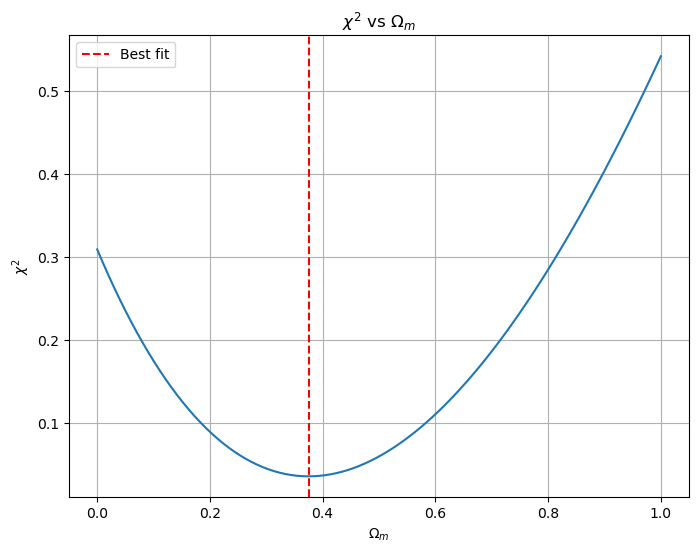

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Hubble parameter
def Hubble_parameter(z, omega_m):
    return 67.8 * np.sqrt(omega_m*(1+z)**3 + (1-omega_m))

# Chi-square function
def chi_square(omega_m, z_data, H0_data):
    chi_sq = 0

    for z, H0_observed in zip(z_data, H0_data):
        H0_predicted = Hubble_parameter(z, omega_m)
        chi_sq += ((H0_observed - H0_predicted)/H0_observed)**2

    return chi_sq

# Data
z_data = np.array([0.07,0.09,0.12,0.17,0.1791,0.1993,0.2,0.27,0.28,0.35,0.3519,0.3802,0.4])

H0_data = np.array([69,69,68.6,83,75,75,72.9,77,88.8,82.7,83,83,95])

# Minimize chi-square
result = minimize(chi_square, x0=0.3, args=(z_data, H0_data))

omega_m_optimal = result.x[0]
min_chi_square = result.fun

print("Optimal omega_m =", omega_m_optimal)
print("Minimum chi-square =", min_chi_square)

# Plot
omega_m_values = np.linspace(0,1,100)
chi_square_values = [chi_square(om, z_data, H0_data) for om in omega_m_values]

plt.figure(figsize=(8,6))
plt.plot(omega_m_values, chi_square_values)
plt.axvline(omega_m_optimal, color='red', linestyle='--', label='Best fit')
plt.xlabel(r'$\Omega_m$')
plt.ylabel(r'$\chi^2$')
plt.title(r'$\chi^2$ vs $\Omega_m$')
plt.grid(True)
plt.legend()
plt.show()

Optimal Omega_m = 0.35286955424543465
Optimal Omega_Lambda = 0.6591613681590082
Minimum chi-square = 1.5711147067486797
Reduced chi-square (dof = N-2) = 0.14282860970442543


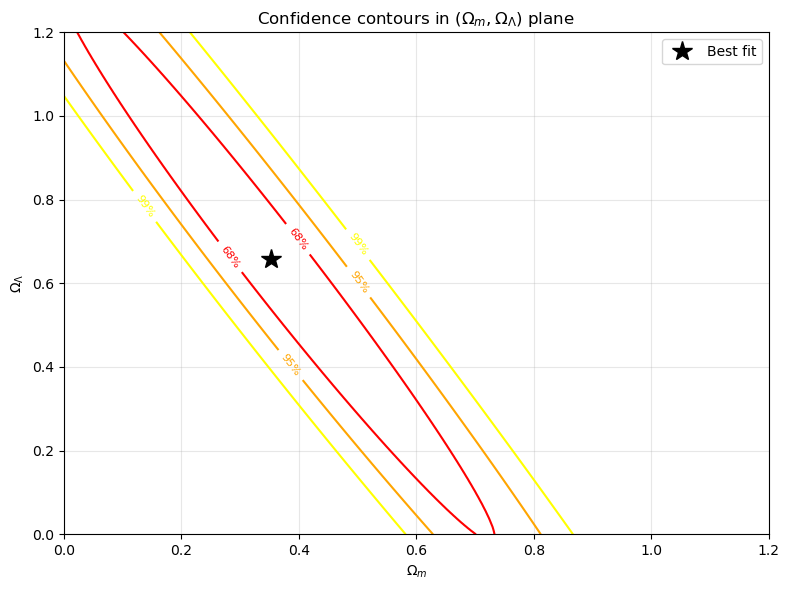

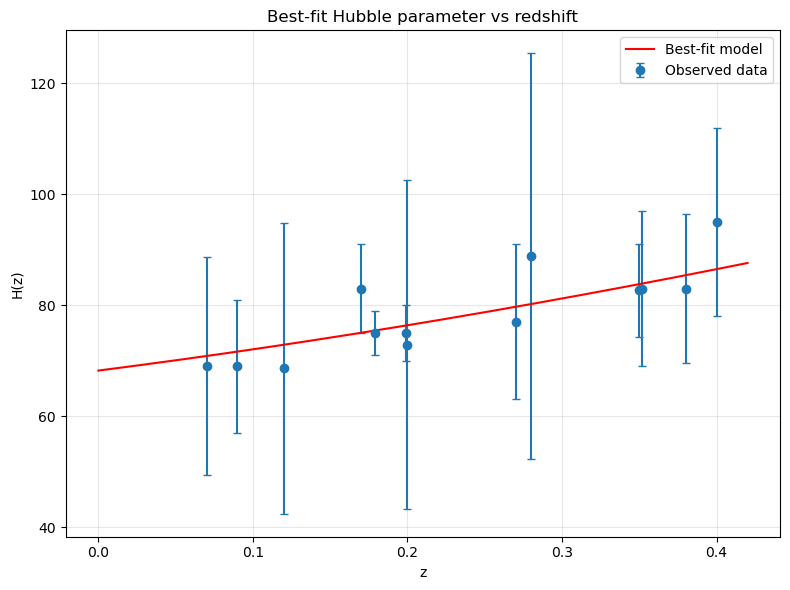

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Theoretical Hubble parameter: H(z) = H0 * sqrt(Om*(1+z)^3 + OL)
H0 = 67.8

def Hubble_parameter(z, omega_m, omega_L):
    return H0 * np.sqrt(omega_m*(1+z)**3 + omega_L)

# Chi-square function (now a function of TWO parameters: omega_m, omega_L)
def chi_square(params, z_data, H_data, sigma_data):
    omega_m, omega_L = params
    H_pred = Hubble_parameter(z_data, omega_m, omega_L)
    chi_sq = np.sum(((H_data - H_pred) / sigma_data)**2)
    return chi_sq

# Data
z_data = np.array([0.07, 0.09, 0.12, 0.17, 0.1791, 0.1993,0.2, 0.27, 0.28, 0.35, 0.3519, 0.3802, 0.4])
H_data = np.array([69, 69, 68.6, 83, 75, 75,72.9, 77, 88.8, 82.7, 83, 83, 95])
sigma_data = np.array([19.6, 12, 26.2, 8, 4, 5,29.6, 14, 36.6, 8.4, 14, 13.5, 17])

# Minimize chi-square over (omega_m, omega_L)
x0 = [0.3, 0.7]  # initial guess
result = minimize(chi_square, x0=x0, args=(z_data, H_data, sigma_data),
                   bounds=[(0, 1.5), (0, 1.5)])

omega_m_optimal, omega_L_optimal = result.x
min_chi_square = result.fun

print("Optimal Omega_m =", omega_m_optimal)
print("Optimal Omega_Lambda =", omega_L_optimal)
print("Minimum chi-square =", min_chi_square)
print("Reduced chi-square (dof = N-2) =", min_chi_square/(len(z_data)-2))

# ---- Contour plot of chi-square in (Omega_m, Omega_Lambda) space ----
om_vals = np.linspace(0, 1.2, 200)
oL_vals = np.linspace(0, 1.2, 200)
OM, OL = np.meshgrid(om_vals, oL_vals)

chi2_grid = np.zeros_like(OM)
for i in range(OM.shape[0]):
    for j in range(OM.shape[1]):
        chi2_grid[i, j] = chi_square([OM[i, j], OL[i, j]], z_data, H_data, sigma_data)

# Delta chi-square contours (for 2 parameters: 68%, 95%, 99% ~ 2.30, 6.17, 11.8)
delta_chi2 = chi2_grid - min_chi_square

plt.figure(figsize=(8, 6))
cp = plt.contour(OM, OL, delta_chi2, levels=[2.30, 6.17, 11.8],
                  colors=['red', 'orange', 'yellow'])
plt.clabel(cp, inline=True, fontsize=8, fmt={2.30: '68%', 6.17: '95%', 11.8: '99%'})
plt.plot(omega_m_optimal, omega_L_optimal, 'k*', markersize=15, label='Best fit')
plt.xlabel(r'$\Omega_m$')
plt.ylabel(r'$\Omega_\Lambda$')
plt.title(r'Confidence contours in $(\Omega_m, \Omega_\Lambda)$ plane')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Best-fit model vs data ----
z_smooth = np.linspace(0, 0.42, 200)
H_smooth = Hubble_parameter(z_smooth, omega_m_optimal, omega_L_optimal)

plt.figure(figsize=(8, 6))
plt.errorbar(z_data, H_data, yerr=sigma_data, fmt='o', label='Observed data', capsize=3)
plt.plot(z_smooth, H_smooth, 'r-', label='Best-fit model')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.title('Best-fit Hubble parameter vs redshift')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()